**PASS: fresh instructor execution.** All saved outputs below came from this notebook's actual code. Run UTC: `2026-11-04T15:25:50.356175+00:00`; executed 5/5 code cells; 7 output objects. This validates the displayed computations; the described synthetic scope still applies.
<!-- canonical-execution-status:end -->

# 04 · Optional image-to-sequence lab: an honest synthetic experiment

**Optional project bridge · CPU · four known 5×5 glyph templates · fixed three-symbol sequences.**
This is a controlled demonstration of a visual encoder, causal decoder, teacher forcing, and sequence evaluation.
It is not evidence of real handwriting recognition, Chữ Nôm OCR, unseen-character generalization, or variable-length robustness.
Training, test seeds, noise levels, decoding policies, and the baseline are declared before fitting.

In [1]:
from pathlib import Path
import sys, math, time, statistics, json
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src/vgu_transformers.py').is_file(), 'Run from REHEARSAL_READY or its notebooks directory.'
sys.path.insert(0, str(ROOT / 'src'))
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
import vgu_transformers as vgu
from vgu_transformers import *
torch.manual_seed(9)
torch.set_num_threads(1)
FIGURES=ROOT/'verification/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'figure.facecolor':'white','axes.facecolor':'white'})
print('PyTorch:',torch.__version__,'| device: CPU | threads:',torch.get_num_threads())
print('Actual imported source:',Path(vgu.__file__).resolve().relative_to(ROOT))
assert Path(vgu.__file__).resolve()==(ROOT/'src/vgu_transformers.py').resolve()

PyTorch: 2.10.0+cpu | device: CPU | threads: 1
Actual imported source: src/vgu_transformers.py


## 1. Declare the question, baseline, and held-out samples first

Does a tiny encoder–decoder learn this fixed synthetic mapping? Compare it with a no-training nearest-template classifier.
Both know the same four clean templates; the baseline classifies each position independently.
Train on fresh noisy batches for **60 optimizer steps**, seed 11, batch 24, bit-flip noise 0.06.
Test all three methods on the **same 16 cases**, seed 987001, noise 0.06.
A predeclared stress set uses 16 cases, seed 987002, noise 0.25; it is not used for fitting or selecting checkpoints.
Disjoint RNG seeds mean independently generated noise/examples, not unseen glyph classes or necessarily unseen label sequences.

In [2]:
from teaching_demos import nearest_template_predict
training={'steps':60,'batch':24,'seed':11,'noise':.06,'lr':.003}
test_images,test_labels=make_glyph_batch(n=16,length=3,seed=987001,noise=.06)
stress_images,stress_labels=make_glyph_batch(n=16,length=3,seed=987002,noise=.25)
print('declared training:',training)
print('test: n=16 sequences, 48 reference symbols, seed=987001, bit-flip noise=0.06')
print('stress: n=16 sequences, 48 reference symbols, seed=987002, bit-flip noise=0.25')
xi,yi=make_decoder_labels(test_labels[:2])
print('two references:',test_labels[:2].tolist())
print('shifted decoder inputs:',xi.tolist(),'targets (include EOS):',yi.tolist())
model=GlyphSeq2Seq()
preview=model(test_images[:2],xi)
print('images [B,S,C,H,W]:',tuple(test_images[:2].shape),'logits [B,T,V]:',tuple(preview.shape))
assert preview.shape==(2,4,7)

declared training: {'steps': 60, 'batch': 24, 'seed': 11, 'noise': 0.06, 'lr': 0.003}
test: n=16 sequences, 48 reference symbols, seed=987001, bit-flip noise=0.06
stress: n=16 sequences, 48 reference symbols, seed=987002, bit-flip noise=0.25
two references: [[2, 0, 3], [0, 0, 3]]
shifted decoder inputs: [[4, 2, 0, 3], [4, 0, 0, 3]] targets (include EOS): [[2, 0, 3, 5], [0, 0, 3, 5]]
images [B,S,C,H,W]: (2, 3, 1, 5, 5) logits [B,T,V]: (2, 4, 7)


## 2. Fit and show the actual training loss

The decoder predicts the next symbol while attending to visual source features.
Training loss includes the EOS target and explicitly ignores PAD. Training loss is not held-out recognition accuracy.
The curve below includes all 60 recorded values, without smoothing or a selected subsequence.

CPU training seconds: 4.085
first loss: 2.0232412815093994 last loss: 0.006463388446718454
loss values at steps 1, 10, 20, 30, 40, 50, 60: [2.0232412815093994, 1.0763474702835083, 0.6407694816589355, 0.2130153328180313, 0.06233865022659302, 0.08639708161354065, 0.006463388446718454]


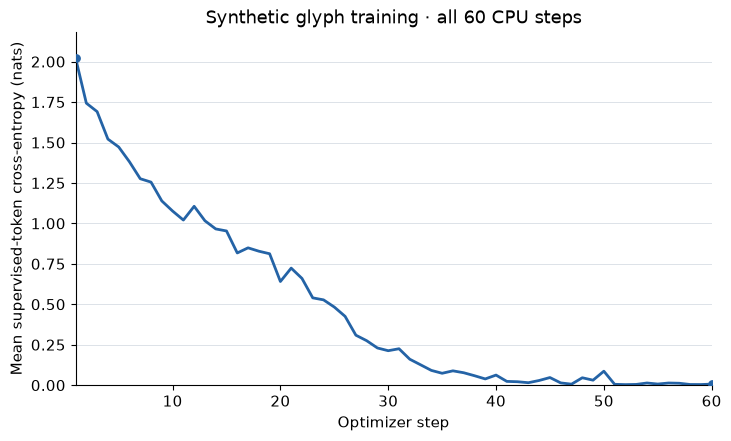

1361

In [3]:
start=time.perf_counter()
model,losses=train_glyph_demo(**training)
training_seconds=time.perf_counter()-start
assert len(losses)==60 and all(math.isfinite(v) for v in losses)
print('CPU training seconds:',round(training_seconds,3))
print('first loss:',losses[0],'last loss:',losses[-1])
print('loss values at steps 1, 10, 20, 30, 40, 50, 60:',[losses[i-1] for i in (1,10,20,30,40,50,60)])
fig,ax=plt.subplots(figsize=(7.2,4.3),layout='constrained')
ax.plot(range(1,61),losses,color='#2463a6',linewidth=2)
ax.scatter([1,60],[losses[0],losses[-1]],color='#2463a6',s=28,zorder=3)
ax.set(xlabel='Optimizer step',ylabel='Mean supervised-token cross-entropy (nats)',
       title='Synthetic glyph training · all 60 CPU steps',xlim=(1,60),ylim=(0,max(losses)*1.08))
ax.grid(axis='y',color='#dce2e8',linewidth=.7)
fig.savefig(FIGURES/'glyph_training_loss.png',dpi=160)
display(fig);plt.close(fig)
(ROOT/'verification/glyph_training_losses.json').write_text(json.dumps(losses,indent=2)+'\n')

## 3. Same examples, declared decoding, inspectable mistakes

Greedy and beam width **3** use max **5 generated tokens** and stop at EOS.
Beam length exponent is explicitly **alpha=0** (raw log-probability ranking).
Normalize output by removing only a leading BOS and stopping at EOS; internal BOS/PAD errors are retained.
Report character edit distance / **48 reference symbols** (CER) and correct full sequences / **16** (exact match).
These labels have equal length, so token-weighted CER equals the mean per-sequence CER here.
CER may exceed one because insertions count. Zero observed errors at n=16 does not establish zero population error.

In [4]:
def compare_methods(images,labels,split):
    truths=labels.tolist()
    greedy_raw=greedy_generate(model,images,max_len=5).tolist()
    beam_raw=[beam_generate_one(model,images[i:i+1],beam_width=3,alpha=0.,max_len=5)[0]
              for i in range(len(images))]
    predictions={'nearest_template':nearest_template_predict(images).tolist(),
                 'greedy':[tokens_before_eos(row) for row in greedy_raw],
                 'beam3_alpha0':[tokens_before_eos(row) for row in beam_raw]}
    report={}
    denominator=sum(len(row) for row in truths)
    for method,preds in predictions.items():
        edits=int(round(sum(cer(t,p)*len(t) for t,p in zip(truths,preds))))
        exact=sum(t==p for t,p in zip(truths,preds))
        row={'split':split,'method':method,'n_sequences':len(truths),
             'reference_symbols':denominator,'edit_count':edits,'cer':edits/denominator,
             'exact_count':exact,'exact_match':exact/len(truths)}
        report[method]=row
        print(json.dumps(row))
    print('All cases: index | reference | nearest-template | greedy | beam3')
    for i,t in enumerate(truths):
        print(i,t,predictions['nearest_template'][i],predictions['greedy'][i],predictions['beam3_alpha0'][i])
    errors=[{'index':i,'reference':t,'greedy':predictions['greedy'][i],'beam3':predictions['beam3_alpha0'][i]}
            for i,t in enumerate(truths)
            if t!=predictions['greedy'][i] or t!=predictions['beam3_alpha0'][i]]
    print('Neural-decoder error cases:',errors if errors else f'none observed in these {len(truths)} cases')
    print('Rows without EOS: greedy',sum(EOS not in row for row in greedy_raw),
          'beam3',sum(EOS not in row for row in beam_raw))
    return {'metrics':report,'references':truths,'predictions':predictions,'neural_errors':errors}
test_report=compare_methods(test_images,test_labels,'declared_test_noise_0.06')

{"split": "declared_test_noise_0.06", "method": "nearest_template", "n_sequences": 16, "reference_symbols": 48, "edit_count": 0, "cer": 0.0, "exact_count": 16, "exact_match": 1.0}
{"split": "declared_test_noise_0.06", "method": "greedy", "n_sequences": 16, "reference_symbols": 48, "edit_count": 0, "cer": 0.0, "exact_count": 16, "exact_match": 1.0}
{"split": "declared_test_noise_0.06", "method": "beam3_alpha0", "n_sequences": 16, "reference_symbols": 48, "edit_count": 0, "cer": 0.0, "exact_count": 16, "exact_match": 1.0}
All cases: index | reference | nearest-template | greedy | beam3
0 [2, 0, 3] [2, 0, 3] [2, 0, 3] [2, 0, 3]
1 [0, 0, 3] [0, 0, 3] [0, 0, 3] [0, 0, 3]
2 [3, 3, 0] [3, 3, 0] [3, 3, 0] [3, 3, 0]
3 [1, 2, 0] [1, 2, 0] [1, 2, 0] [1, 2, 0]
4 [3, 0, 1] [3, 0, 1] [3, 0, 1] [3, 0, 1]
5 [3, 3, 1] [3, 3, 1] [3, 3, 1] [3, 3, 1]
6 [2, 2, 1] [2, 2, 1] [2, 2, 1] [2, 2, 1]
7 [1, 2, 0] [1, 2, 0] [1, 2, 0] [1, 2, 0]
8 [0, 3, 3] [0, 3, 3] [0, 3, 3] [0, 3, 3]
9 [2, 1, 3] [2, 1, 3] [2, 1, 3]

## 4. The predeclared harder noise check

Evaluate the fitted model and baseline without additional training. This tests more pixel corruption of the **same four templates**.
It remains distinct from unseen writers, new alphabets, changed segmentation, or real scan artifacts.
Read the actual errors below; do not claim a beam improvement unless the same-case comparison shows it.

In [5]:
stress_report=compare_methods(stress_images,stress_labels,'predeclared_stress_noise_0.25')
evidence={'training':training,'training_seconds':training_seconds,'losses':losses,
          'decoding':{'beam_width':3,'alpha':0.,'max_generated_tokens':5},
          'declared_test':test_report,'predeclared_stress':stress_report}
(ROOT/'verification/glyph_experiment.json').write_text(json.dumps(evidence,indent=2)+'\n')
assert cer([0],[0,1,2])==2.
assert tokens_before_eos([BOS,0,PAD,EOS])==[0,PAD]
print('Metric sanity check: reference [0], hypothesis [0,1,2] -> CER',cer([0],[0,1,2]))
print('Evidence saved with all references and predictions; no task-accuracy claim is inferred from training loss alone.')

{"split": "predeclared_stress_noise_0.25", "method": "nearest_template", "n_sequences": 16, "reference_symbols": 48, "edit_count": 6, "cer": 0.125, "exact_count": 11, "exact_match": 0.6875}
{"split": "predeclared_stress_noise_0.25", "method": "greedy", "n_sequences": 16, "reference_symbols": 48, "edit_count": 7, "cer": 0.14583333333333334, "exact_count": 9, "exact_match": 0.5625}
{"split": "predeclared_stress_noise_0.25", "method": "beam3_alpha0", "n_sequences": 16, "reference_symbols": 48, "edit_count": 7, "cer": 0.14583333333333334, "exact_count": 9, "exact_match": 0.5625}
All cases: index | reference | nearest-template | greedy | beam3
0 [1, 2, 3] [1, 2, 3] [1, 2, 3] [1, 2, 3]
1 [3, 3, 3] [2, 3, 3] [2, 3, 3] [2, 3, 3]
2 [0, 2, 3] [0, 2, 3] [0, 2, 3] [0, 2, 3]
3 [0, 2, 2] [0, 2, 2] [0, 2, 2] [0, 2, 2]
4 [1, 0, 0] [1, 0, 0] [1, 0, 0] [1, 0, 0]
5 [0, 0, 0] [0, 0, 0] [0, 0, 0] [0, 0, 0]
6 [1, 0, 2] [1, 3, 2] [1, 3, 2] [1, 3, 2]
7 [1, 3, 2] [1, 3, 3] [1, 3, 3] [1, 3, 3]
8 [1, 3, 3] [1, 3

## How to turn the toy into a research question

Compare the actual baseline and neural results before deciding a Transformer is necessary.
This toy has only four templates and 64 possible three-symbol label sequences; a nearest-template system can be strong.
A useful next experiment declares an unfamiliar-writer or unfamiliar-template split, variable lengths, realistic corruptions,
multiple training seeds, uncertainty, and a failure taxonomy before collecting results.
Explain what the visual encoder contributes, what the target causal mask blocks, and why source cross-attention may see all source positions.
Use real data only with a documented dataset, evaluation protocol, and provenance; this synthetic demo supplies none of that external evidence.